## Recomendación: Factores latentes (ALS)

- Factorización de la matriz implícita con **ALS** de Spark MLlib (`implicitPrefs=True`)

- Cada entidad y cada proveedor se representan con `rank` factores; puntaje(e, p) = u_e · v_p

### Constantes

- `RANGO_RANK`: número de factores latentes

- `RANGO_REG`: regularización L2 de los factores

- `RANGO_ALPHA`: confianza de una interacción observada, c = 1 + α · señal

- `RANGO_ITER`: iteraciones de ALS para la curva de convergencia; `SEMILLAS`: semillas para medir la estabilidad

- `ITER` = 15: iteraciones del modelo (se justifica en la sección 3)

In [1]:
RANGO_RANK = [32, 64, 128]
RANGO_REG = [0.1, 1.0, 10.0]
RANGO_ALPHA = [10, 40, 100]
RANGO_ITER = [5, 10, 15, 20]
SEMILLAS = [42, 7, 13]
ITER = 15

### Utilidades

In [2]:
NOTEBOOK = "d_als"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [4]:
from pyspark.ml.recommendation import ALS

def ajustar(c, senal, rank, reg, alpha, iters=ITER, seed=SEED):
    d = spark.createDataFrame(c["tr"].assign(r=SENALES[senal](c["tr"]))[["entidad_idx", "proveedor_idx", "r"]])
    als = ALS(rank=rank, regParam=reg, alpha=alpha, maxIter=iters, seed=seed, implicitPrefs=True,
              userCol="entidad_idx", itemCol="proveedor_idx", ratingCol="r", coldStartStrategy="drop")
    return als.fit(d)

def factores(m, n, rank):
    f = m.userFactors if n == "entidad" else m.itemFactors
    pdf = f.toPandas()
    M = np.zeros((cfg["n_entidades"] if n == "entidad" else cfg["n_proveedores"], rank), dtype=np.float32)
    M[pdf.id.to_numpy()] = np.vstack(pdf.features.to_numpy())
    return M

def puntaje_als(m, rank):
    U, V = factores(m, "entidad", rank), factores(m, "proveedor", rank)
    return lambda idx: U[idx] @ V.T

### Carga

In [5]:
cfg = leer_config()
ctx = {(p, s): contexto(p, s) for p in PARTICIONES for s in SENALES}
c = ctx[("val", SENAL)]
print(f"val: {c['X'].nnz:,} pares | test: {ctx[('test', SENAL)]['X'].nnz:,} pares | señal {SENAL}")

val: 51,185 pares | test: 96,022 pares | señal binaria


---
### **1. Grilla: `rank`, `regParam` y `alpha`**

- Se entrena con 2023 y se mide NDCG@10 sobre los pares nuevos de 2024

In [6]:
grilla = []
for rank in RANGO_RANK:
    for reg in RANGO_REG:
        for alpha in RANGO_ALPHA:
            t0 = time.time()
            m = ajustar(c, SENAL, rank, reg, alpha)
            recs = top_k(puntaje_als(m, rank), c["entidades"], c["vistos"], c["catalogo"], k=K_EVAL)
            grilla.append({"rank": rank, "reg": reg, "alpha": alpha, **evaluar(recs, c["pos"], c["catalogo"].sum()),
                           "seg": round(time.time() - t0, 1)})
grilla = pd.DataFrame(grilla)
grilla.sort_values("ndcg@10", ascending=False).head(8)

,rank,reg,alpha,precision@10,recall@10,ndcg@10,hit@10,cobertura,seg
13,64,1.0,40,0.0560,0.1233,0.1111,0.3920,0.4929,16.9
9,64,0.1,10,0.0574,0.1180,0.1089,0.3935,0.3020,16.5
12,64,1.0,10,0.0579,0.1145,0.1084,0.3870,0.4273,16.4
18,128,0.1,10,0.0547,0.1249,0.1078,0.3910,0.5108,79.9
21,128,1.0,10,0.0555,0.1223,0.1075,0.3905,0.6016,81.2
10,64,0.1,40,0.0537,0.1185,0.1059,0.3791,0.4401,16.5
4,32,1.0,40,0.0553,0.1151,0.1049,0.3801,0.3142,9.0
1,32,0.1,40,0.0542,0.1167,0.1026,0.3782,0.2453,10.3


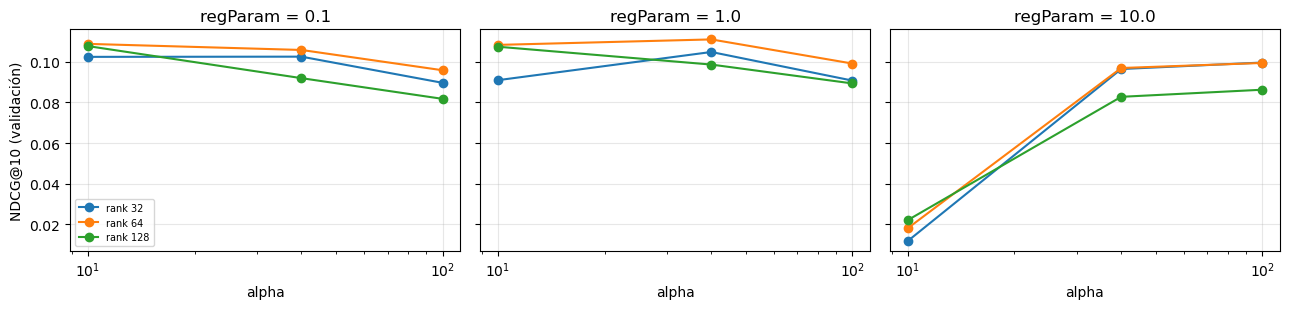

In [7]:
fig, ax = plt.subplots(1, len(RANGO_REG), figsize=(13, 3.2), sharey=True)
for i, reg in enumerate(RANGO_REG):
    for rank in RANGO_RANK:
        d = grilla[(grilla.reg == reg) & (grilla["rank"] == rank)]
        ax[i].plot(d.alpha, d["ndcg@10"], "o-", label=f"rank {rank}")
    ax[i].set_xscale("log"); ax[i].set_title(f"regParam = {reg}"); ax[i].set_xlabel("alpha")
ax[0].set_ylabel("NDCG@10 (validación)"); ax[0].legend(fontsize=7)
mostrar_fig("grilla_als")

- **Mejor: rank 64, regParam 1.0, alpha 40** (NDCG@10 = 0.111), en el interior de la grilla

- Rank 128 no mejora y tarda ~4× más (80 s por modelo)

- regParam = 10 con alpha = 10 colapsa (NDCG < 0.03): demasiada regularización para la poca confianza

---
### **2. Señal**

Con los parámetros elegidos, se compara la señal binaria contra las de intensidad

In [8]:
senales = []
for s in SENALES:
    cs = ctx[("val", s)]
    m = ajustar(cs, s, RANK, REG, ALPHA)
    recs = top_k(puntaje_als(m, RANK), cs["entidades"], cs["vistos"], cs["catalogo"], k=K_EVAL)
    senales.append({"senal": s, **evaluar(recs, cs["pos"], cs["catalogo"].sum())})
senales = pd.DataFrame(senales)
senales

,senal,precision@10,recall@10,ndcg@10,hit@10,cobertura
0,binaria,0.0560,0.1233,0.1111,0.3920,0.4929
1,n_adj,0.0581,0.1262,0.1141,0.4063,0.4772
2,log_monto,0.0411,0.0862,0.0768,0.3045,0.5150


- `n_adj` da 0.114 y binaria 0.111 (una diferencia de ~2 desviaciones entre semillas); `log_monto` cae a 0.077

- Se mantiene la **binaria** como señal común de todos los modelos; el monto premia obras grandes, no afinidad

---
### **3. Convergencia y estabilidad**

- **Iteraciones:** NDCG y tiempo al aumentar `maxIter`

- **Semillas:** solapamiento del top-10 entre semillas (Jaccard medio por entidad); 1 = mismas listas

In [9]:
conv = []
for it in RANGO_ITER:
    t0 = time.time(); m = ajustar(c, SENAL, RANK, REG, ALPHA, iters=it)
    recs = top_k(puntaje_als(m, RANK), c["entidades"], c["vistos"], c["catalogo"], k=K_EVAL)
    conv.append({"iteraciones": it, **evaluar(recs, c["pos"], c["catalogo"].sum()), "seg": round(time.time() - t0, 1)})
conv = pd.DataFrame(conv)

listas, ndcg_sem = {}, []
for sd in SEMILLAS:
    m = ajustar(c, SENAL, RANK, REG, ALPHA, seed=sd)
    r = top_k(puntaje_als(m, RANK), c["entidades"], c["vistos"], c["catalogo"], k=K_EVAL)
    listas[sd] = r.groupby("entidad_idx").proveedor_idx.apply(set)
    ndcg_sem.append(evaluar(r, c["pos"], c["catalogo"].sum())["ndcg@10"])
jac = [np.mean([len(listas[a][e] & listas[b][e]) / len(listas[a][e] | listas[b][e]) for e in listas[a].index])
       for i, a in enumerate(SEMILLAS) for b in SEMILLAS[i + 1:]]
estabilidad = pd.DataFrame([{"jaccard_top10_medio": round(np.mean(jac), 3), "jaccard_min": round(min(jac), 3),
                             "ndcg_media": round(np.mean(ndcg_sem), 4), "ndcg_desv": round(np.std(ndcg_sem), 4)}])
display(conv); estabilidad

,iteraciones,precision@10,recall@10,ndcg@10,hit@10,cobertura,seg
0,5,0.0482,0.1022,0.0927,0.3396,0.4282,9.1
1,10,0.0541,0.1189,0.1084,0.3811,0.4803,13.1
2,15,0.0560,0.1233,0.1111,0.3920,0.4929,16.9
3,20,0.0563,0.1234,0.1115,0.3945,0.4980,20.9


,jaccard_top10_medio,jaccard_min,ndcg_media,ndcg_desv
0,0.441,0.435,0.1093,0.0014


- El NDCG se estabiliza en **15 iteraciones** (0.111 vs 0.112 con 20, con 25% más de tiempo)

- **Estabilidad:** NDCG casi idéntico entre semillas (desviación 0.001), aunque las listas solo se solapan en ~44%

- El orden fino cambia con la semilla, pero la calidad del ranking no

In [10]:
cfg["als"] = {"rank": RANK, "reg": REG, "alpha": ALPHA, "iter": ITER}
guardar_config(cfg)

---
### **4. Evaluación en test**

- Se re-entrena con 2023-2024 y se guardan los top-`N_CAND` de validación y de test

In [11]:
evaluacion, modelos = [], {}
for p in PARTICIONES:
    cp = ctx[(p, SENAL)]
    t0 = time.time(); modelos[p] = m = ajustar(cp, SENAL, RANK, REG, ALPHA)
    recs = top_k(puntaje_als(m, RANK), cp["entidades"], cp["vistos"], cp["catalogo"])
    guardar_recs(recs, f"als_{p}")
    evaluacion.append({"particion": p, "modelo": "als", **evaluar(recs, cp["pos"], cp["catalogo"].sum()), "seg": round(time.time() - t0, 1)})
evaluacion = pd.DataFrame(evaluacion)
evaluacion

,particion,modelo,precision@10,recall@10,ndcg@10,hit@10,cobertura,seg
0,val,als,0.0561,0.1234,0.1110,0.3925,0.4929,16.9
1,test,als,0.0435,0.1144,0.0943,0.3385,0.2972,25.5


- **ALS en test: NDCG@10 = 0.094**, recall@10 = 0.114

- Prácticamente empata con el user-user (0.095), con más recall (0.114 vs 0.104): acierta más, pero más abajo en la lista

---
### **5. Espacio latente**

- Puntaje de las relaciones **existentes** (2023-2024): qué tan bien las explica el patrón general (insumo de afinidades inusuales)

- Vecinos de un proveedor en el espacio de factores (insumo de sustitutos)

In [12]:
U, V = factores(modelos["test"], "entidad", RANK), factores(modelos["test"], "proveedor", RANK)
tr = ctx[("test", SENAL)]["tr"]
existentes = tr[["entidad_idx", "proveedor_idx", "n_adj", "monto"]].assign(
    score=np.einsum("ij,ij->i", U[tr.entidad_idx], V[tr.proveedor_idx]))
existentes["percentil"] = existentes.score.rank(pct=True).round(4)
print(f"puntaje de relaciones existentes p05/p50/p95: {existentes.score.quantile([.05, .5, .95]).round(3).tolist()}")

prov = pd.read_parquet(datos_dir / "proveedores")
cat = ctx[("test", SENAL)]["catalogo"]
p0 = int(prov.index[prov.proveedor_key == "RUC:20501887286"][0])
Vn = V / np.linalg.norm(V, axis=1, keepdims=True).clip(1e-9)
cols = np.flatnonzero(cat)
sim = Vn[cols] @ Vn[p0]
top = cols[np.argsort(-sim)[1:9]]
vecinos_lat = prov.loc[top, ["proveedor_key", "nombre"]].assign(coseno=(Vn[top] @ Vn[p0]).round(3))
print("proveedor:", prov.nombre[p0])
vecinos_lat

puntaje de relaciones existentes p05/p50/p95: [0.31, 0.76, 0.93]
proveedor: DIAGNOSTICA PERUANA S.A.C.


,proveedor_key,nombre,coseno
24,RUC:20377339461,B.BRAUN MEDICAL PERU S.A.,0.912
20,RUC:20553853355,SIMED PERU S.A.C.,0.895
38,RUC:20392764373,DROGUERIA CADILLO S.A.C,0.887
85,RUC:20100018625,MEDIFARMA S A,0.877
30,RUC:20155695901,SISTEMAS ANALITICOS SRL,0.858
71,RUC:20468787360,ROCHEM BIOCARE DEL PERU S.A.C,0.845
88,RUC:20506744874,MEDICAL CHANNEL S.A.C.,0.837
44,RUC:20505110651,W.P. BIOMED SOCIEDAD ANONIMA,0.833


- Las relaciones existentes tienen puntaje mediano 0.76; el 5% más bajo queda bajo 0.31

- Los vecinos de Diagnóstica Peruana en el espacio latente son **proveedores de salud** (B. Braun, Simed, Medifarma)

- Coinciden con los de contenido sin haber leído texto: **mismas entidades compradoras**

---
### **6. Escritura de datos**

- `temp/datos/als_entidad.npy`, `als_proveedor.npy`: factores del modelo de test

- `temp/datos/als_existentes`: puntaje y percentil de cada relación 2023-2024

- `temp/datos/recs_als_<particion>`: top-`N_CAND` por entidad

In [13]:
np.save(datos_dir / "als_entidad.npy", U)
np.save(datos_dir / "als_proveedor.npy", V)
existentes.to_parquet(datos_dir / "als_existentes", index=False)

#### a. Verificación

In [14]:
for p in PARTICIONES:
    cp = ctx[(p, SENAL)]
    r = leer_recs(f"als_{p}")
    assert set(r.entidad_idx) == set(cp["pos"]) and cp["catalogo"][r.proveedor_idx].all(), p
    assert cp["vistos"][r.entidad_idx.to_numpy(), r.proveedor_idx.to_numpy()].sum() == 0, p
assert len(existentes) == len(tr) and existentes.score.notna().all()
print(f"recomendaciones dentro del catálogo y sin pares vistos | {len(existentes):,} relaciones puntuadas | OK")

recomendaciones dentro del catálogo y sin pares vistos | 96,022 relaciones puntuadas | OK


---
### **7. Escritura de resultados**

In [15]:
escritos = guardar_tablas({"grilla_als": grilla, "senal_als": senales, "convergencia_als": conv, "estabilidad_als": estabilidad,
                           "evaluacion_als": evaluacion, "vecinos_latentes_ejemplo": vecinos_lat})

Escrito en 03_Recomend/temp/d_als/: grilla_als, senal_als, convergencia_als, estabilidad_als, evaluacion_als, vecinos_latentes_ejemplo


#### a. Verificación

In [16]:
verificar_salidas(escritos)

OK: 6 tablas (parquet + json) | 1 figuras: grilla_als


---
### **8. Cerrar sesión**

In [17]:
spark.stop()